# ДЗ № 2. Прогноз продаж Online Retail

Из ДЗ № 1 беру продажи товара 20728 (LUNCH BAG CARS BLUE) в штуках. Сравниваю пять моделей на дневных, недельных и месячных данных.

## 1. Данные и разбиение

Крайние дни и неполные недели и месяцы убираю по флагам из ДЗ № 1. Нули и большие заказы оставляю. Неделя начинается в понедельник, на графиках недели и месяцы подписаны датой начала.

In [1]:
%matplotlib inline

from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.ensemble import GradientBoostingRegressor
from statsmodels.tsa.ar_model import AutoReg
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.holtwinters import ExponentialSmoothing, SimpleExpSmoothing

settings = {
    "День": ("daily", "D", [1, 7, 31, 61], 90),
    "Неделя": ("weekly", "W-MON", [1, 4, 8], 16),
    "Месяц": ("monthly", "MS", [1, 2], 4),
}
data_dir = Path("data")
results_dir = Path("results")
results_dir.mkdir(exist_ok=True)


def load_sales(file, freq):
    if freq == "D":
        data = pd.read_csv(file, parse_dates=["date"], index_col="date")
        sales = data.loc[~data["boundary_day"], "units_recorded"]
    else:
        data = pd.read_csv(file, parse_dates=["period_start"], index_col="period_start")
        sales = data.loc[data["complete"], "units"]
    expected = pd.date_range(sales.index[0], sales.index[-1], freq=freq)
    if not sales.index.equals(expected) or sales.isna().any() or (sales < 0).any():
        raise ValueError(f"Проверьте даты и значения в {file}")
    return sales.asfreq(freq).astype(float)


series = {}
splits = []
for label, (name, freq, horizons, test_size) in settings.items():
    sales = load_sales(data_dir / f"sales_{name}.csv", freq)
    series[label] = sales
    first_test = len(sales) - test_size
    starts = test_size - max(horizons) + 1
    assert first_test > 0 and starts > 0
    splits.append({
        "Частота": label, "Всего": len(sales), "В первом обучении": first_test,
        "В тесте": test_size, "Начало теста": sales.index[first_test].date(),
        "Конец теста": sales.index[-1].date(), "Точек старта": starts,
    })

display(pd.DataFrame(splits))

,Частота,Всего,В первом обучении,В тесте,Начало теста,Конец теста,Точек старта
0,День,372,282,90,2011-09-10,2011-12-08,30
1,Неделя,52,36,16,2011-08-15,2011-11-28,9
2,Месяц,11,7,4,2011-08-01,2011-11-01,3


Последний отрезок каждого ряда выделяю под тест. В каждой точке старта модель заново обучается на всех уже известных продажах и сразу строит прогноз на максимальный горизонт. Для коротких горизонтов беру начало этого прогноза. Точки старта одинаковы для всех моделей и горизонтов внутри частоты.

## 2. Модели

- **Наивная** повторяет последнюю неделю для дневного ряда и последнее значение для остальных.
- **Сглаживание** учитывает недельный цикл для дневного ряда. Для недель и месяцев беру простое экспоненциальное сглаживание.
- **AutoReg** использует лаги 1 и 7 и день недели для дневного ряда. Для остальных рядов оставляю лаг 1.
- **ARIMA(1, 1, 0)** моделирует изменение продаж относительно предыдущего периода.
- **Градиентный бустинг** использует лаги и скользящее среднее. На дневных данных добавляю день недели.

Для недель и месяцев беру простые модели из-за короткой истории. Параметры заданы заранее.

In [2]:
def naive(train, future):
    period = 7 if train.index.freqstr == "D" else 1
    return np.resize(train.iloc[-period:].to_numpy(), len(future))


def smoothing(train, future):
    if train.index.freqstr == "D":
        model = ExponentialSmoothing(train, seasonal="add", seasonal_periods=7)
    else:
        model = SimpleExpSmoothing(train)
    return model.fit().forecast(len(future))


def autoregression(train, future):
    daily = train.index.freqstr == "D"
    model = AutoReg(
        train, lags=[1, 7] if daily else 1, seasonal=daily,
        period=7 if daily else None,
    )
    return model.fit().forecast(len(future))


def arima(train, future):
    return ARIMA(train, order=(1, 1, 0)).fit().forecast(len(future))


def boost_features(history, date, lags, window, daily):
    row = [history[-lag] for lag in lags]
    row.append(np.mean(history[-window:]))
    if daily:
        row.append(date.dayofweek)
    return row


def boosting(train, future):
    freq = train.index.freqstr
    lags, window = {"D": ([1, 7, 14], 7), "W-MON": ([1, 2, 4], 4), "MS": ([1], 2)}[freq]
    daily = freq == "D"
    start = max(max(lags), window)
    history = train.to_list()
    X = [
        boost_features(history[:i], train.index[i], lags, window, daily)
        for i in range(start, len(train))
    ]
    model = GradientBoostingRegressor(
        n_estimators=60, learning_rate=0.05,
        max_depth=2 if daily else 1, min_samples_leaf=2, random_state=42,
    )
    model.fit(X, history[start:])

    predictions = []
    for date in future:
        row = boost_features(history, date, lags, window, daily)
        prediction = max(0.0, model.predict([row])[0])
        predictions.append(prediction)
        history.append(prediction)
    return predictions


models = {
    "Наивная": naive,
    "Сглаживание": smoothing,
    "AutoReg": autoregression,
    "ARIMA": arima,
    "Градиентный бустинг": boosting,
}

## 3. Прогнозы и метрики

MAE показывает средний промах в штуках, а RMSE сильнее реагирует на большие ошибки. Основная метрика — WAPE: сумма абсолютных ошибок, делённая на сумму фактических продаж. WAPE показывает ошибку относительно объёма продаж и допускает отдельные нулевые значения.

Для горизонта h считаю метрики по всем шагам от 1 до h на общих точках старта. Отдельно показываю MAE только на h-м шаге. В CSV сохраняю весь прогноз до максимального горизонта.

In [3]:
def backtest(sales, label, test_size, max_horizon):
    parts = []
    first_test = len(sales) - test_size
    for start in range(first_test, len(sales) - max_horizon + 1):
        train = sales.iloc[:start]
        actual = sales.iloc[start:start + max_horizon]
        for name, forecast in models.items():
            predicted = np.maximum(0, np.asarray(forecast(train, actual.index)))
            if predicted.shape != (max_horizon,) or not np.isfinite(predicted).all():
                raise ValueError(f"Ошибка прогноза: {label}, {actual.index[0]}, {name}")
            parts.append(pd.DataFrame({
                "frequency": label,
                "model": name,
                "cutoff": actual.index[0],
                "date": actual.index,
                "step": np.arange(1, max_horizon + 1),
                "actual": actual.to_numpy(),
                "forecast": predicted,
            }))
    return pd.concat(parts, ignore_index=True)


def score(forecasts, horizons):
    rows = []
    for name, group in forecasts.groupby("model", sort=False):
        for h in horizons:
            path = group.loc[group["step"] <= h]
            error = path["forecast"] - path["actual"]
            rows.append({
                "frequency": path["frequency"].iloc[0],
                "horizon": h,
                "model": name,
                "origins": path["cutoff"].nunique(),
                "MAE": error.abs().mean(),
                "RMSE": np.sqrt((error ** 2).mean()),
                "WAPE_pct": 100 * error.abs().sum() / path["actual"].sum(),
                "MAE_at_h": error.loc[path["step"] == h].abs().mean(),
            })
    return pd.DataFrame(rows).sort_values(["horizon", "WAPE_pct"])


forecasts = []
scores = []
for label, (_, _, horizons, test_size) in settings.items():
    forecast = backtest(series[label], label, test_size, max(horizons))
    forecasts.append(forecast)
    scores.append(score(forecast, horizons))

predictions = pd.concat(forecasts, ignore_index=True)
metrics = pd.concat(scores, ignore_index=True)
predictions.to_csv(results_dir / "predictions.csv", index=False)
metrics.to_csv(results_dir / "metrics.csv", index=False)

display(metrics.rename(columns={
    "frequency": "Частота", "horizon": "Горизонт", "model": "Модель",
    "origins": "Стартов", "WAPE_pct": "WAPE, %", "MAE_at_h": "MAE на шаге h",
}).round(2))

,Частота,Горизонт,Модель,Стартов,MAE,RMSE,"WAPE, %",MAE на шаге h
0,День,1,AutoReg,30,18.12,28.39,53.03,18.12
1,День,1,Сглаживание,30,20.42,27.91,59.78,20.42
2,День,1,Градиентный бустинг,30,24.94,32.48,73.01,24.94
3,День,1,Наивная,30,25.77,41.58,75.41,25.77
4,День,1,ARIMA,30,28.84,38.33,84.40,28.84
5,День,7,AutoReg,30,17.37,24.80,55.32,16.88
6,День,7,Сглаживание,30,20.26,25.50,64.54,20.36
7,День,7,Градиентный бустинг,30,23.47,28.92,74.76,22.37
8,День,7,Наивная,30,24.01,38.45,76.50,22.83
9,День,7,ARIMA,30,31.52,38.69,100.41,21.99


## 4. Графики

Здесь для каждой частоты показан прогноз из первой точки старта теста. Графики WAPE ниже учитывают все точки старта.

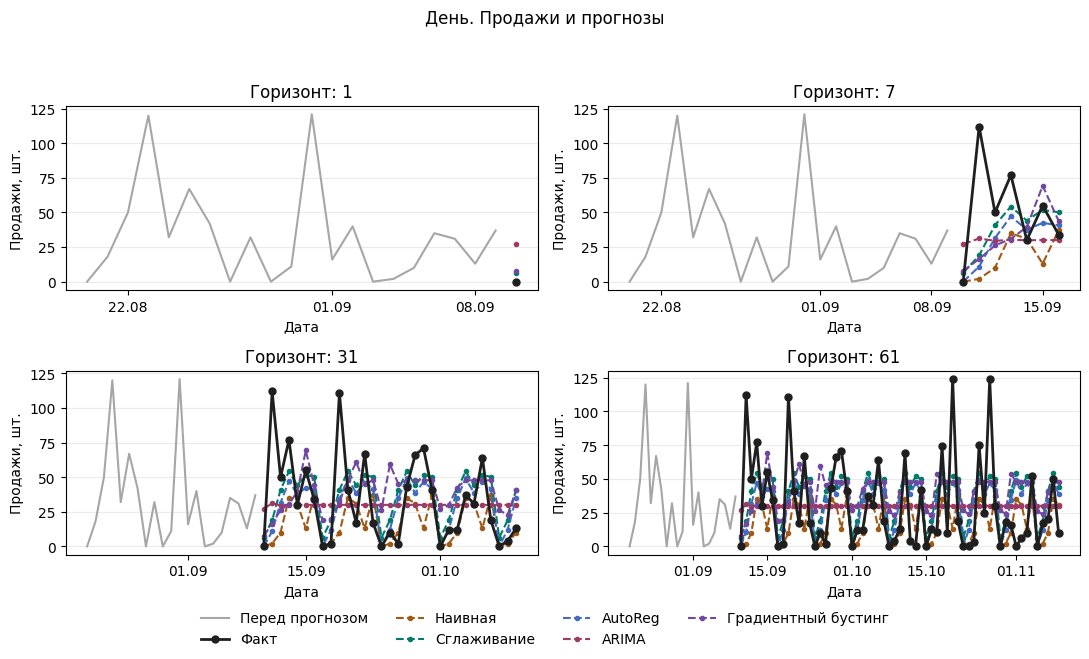

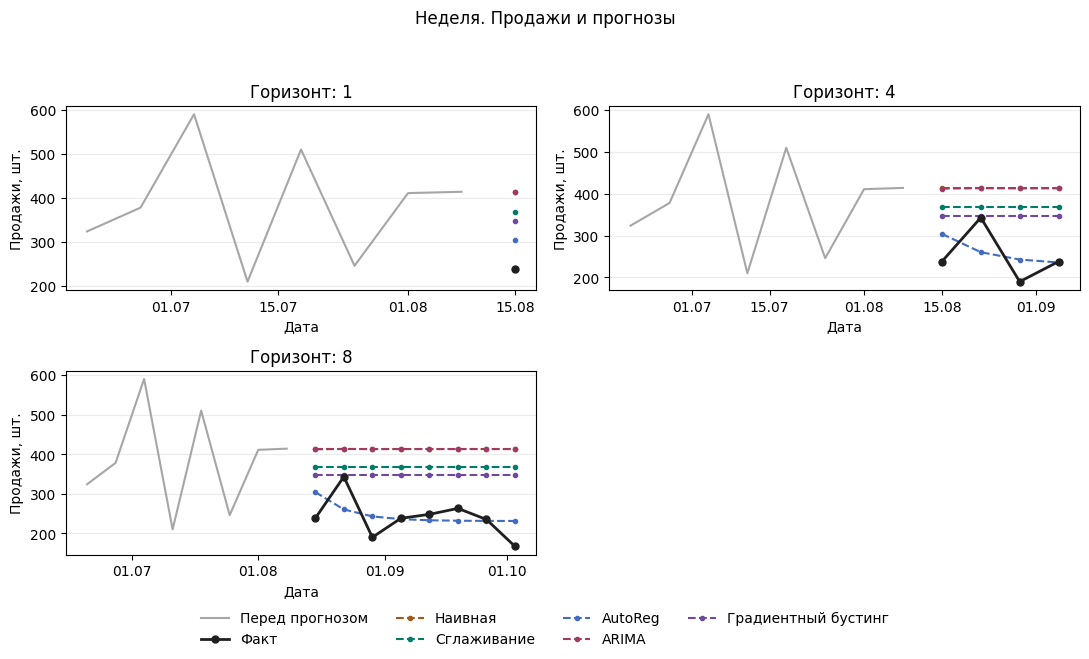

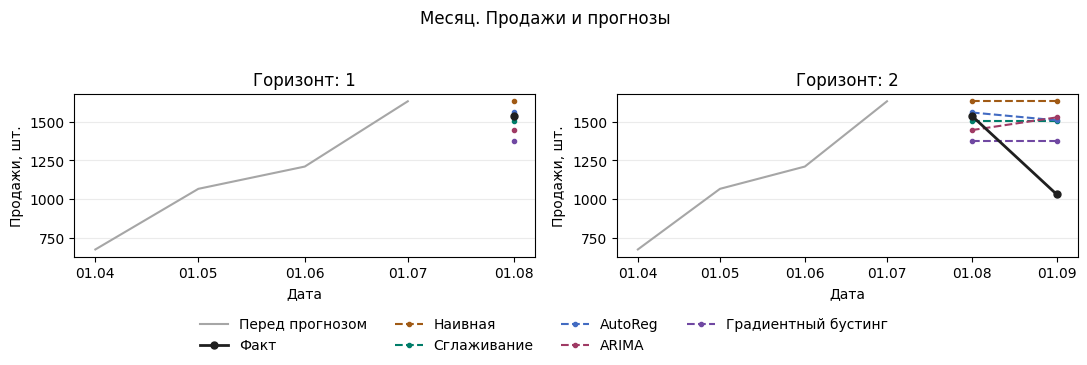

In [4]:
colors = dict(zip(models, ["#a05a15", "#007d69", "#426bc2", "#9f3a64", "#7048a2"]))


def plot_forecasts(predictions, series, label, horizons, lookback):
    data = predictions.loc[predictions["frequency"] == label]
    example = data.loc[data["cutoff"] == data["cutoff"].min()]
    history = series.loc[series.index < example["cutoff"].iloc[0]].tail(lookback)
    rows = (len(horizons) + 1) // 2
    fig, axes = plt.subplots(rows, 2, figsize=(11, 3 * rows + 0.6), squeeze=False)
    for ax, h in zip(axes.flat, horizons):
        path = example.loc[example["step"] <= h]
        actual = path.drop_duplicates("date")
        ax.plot(history.index, history, color="0.65", label="Перед прогнозом")
        ax.plot(actual["date"], actual["actual"], "o-", color="0.12",
                linewidth=2, markersize=5, label="Факт", zorder=10)
        for name, group in path.groupby("model", sort=False):
            ax.plot(group["date"], group["forecast"], "o--", color=colors[name],
                    markersize=3, label=name)
        locator = mdates.AutoDateLocator(minticks=3, maxticks=6)
        ax.xaxis.set_major_locator(locator)
        ax.xaxis.set_major_formatter(mdates.DateFormatter("%d.%m"))
        ax.set(title=f"Горизонт: {h}", xlabel="Дата", ylabel="Продажи, шт.")
        ax.grid(axis="y", alpha=0.25)
    for ax in list(axes.flat)[len(horizons):]:
        ax.set_visible(False)
    handles, names = axes[0, 0].get_legend_handles_labels()
    fig.suptitle(f"{label}. Продажи и прогнозы")
    fig.legend(handles, names, loc="lower center", ncol=4, frameon=False)
    fig.tight_layout(rect=(0, 0.13 / rows, 1, 0.94))
    plt.show()


for label, lookback in zip(settings, [21, 8, 4]):
    plot_forecasts(predictions, series[label], label, settings[label][2], lookback)

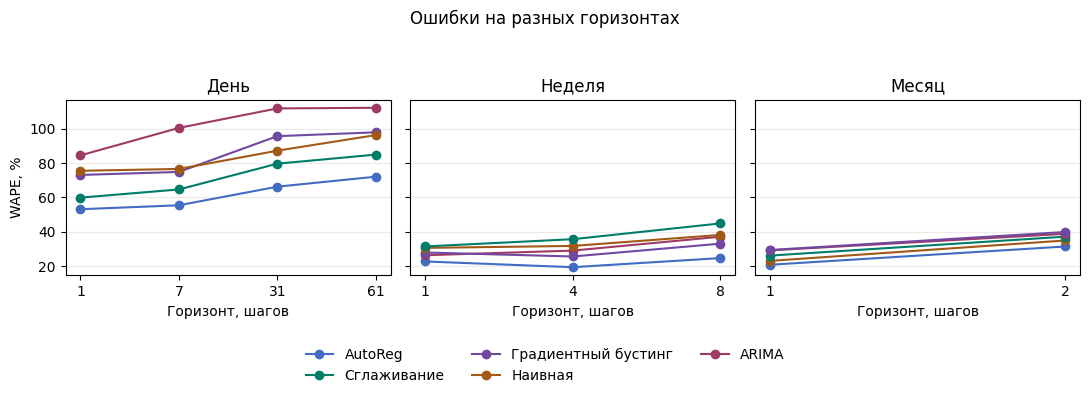

In [5]:
def plot_errors(metrics):
    fig, axes = plt.subplots(1, 3, figsize=(11, 3.9), sharey=True)
    for ax, (label, (_, _, horizons, _)) in zip(axes, settings.items()):
        subset = metrics.loc[metrics["frequency"] == label]
        for name, group in subset.groupby("model", sort=False):
            ax.plot(group["horizon"].astype(str), group["WAPE_pct"],
                    "o-", color=colors[name], label=name)
        ax.set(title=label, xlabel="Горизонт, шагов", xticks=range(len(horizons)))
        ax.grid(axis="y", alpha=0.25)
    axes[0].set_ylabel("WAPE, %")
    handles, names = axes[0].get_legend_handles_labels()
    fig.suptitle("Ошибки на разных горизонтах")
    fig.legend(handles, names, loc="lower center", ncol=3, frameon=False)
    fig.tight_layout(rect=(0, 0.15, 1, 0.93))
    plt.show()


plot_errors(metrics)

## 5. Выводы

Победители по WAPE на каждом горизонте.

In [6]:
best = metrics.loc[
    metrics.groupby(["frequency", "horizon"], sort=False)["WAPE_pct"].idxmin(),
    ["frequency", "horizon", "model", "WAPE_pct"],
]
display(best.rename(columns={
    "frequency": "Частота", "horizon": "Горизонт",
    "model": "Модель", "WAPE_pct": "WAPE, %",
}).reset_index(drop=True).round(2))

,Частота,Горизонт,Модель,"WAPE, %"
0,День,1,AutoReg,53.03
1,День,7,AutoReg,55.32
2,День,31,AutoReg,66.16
3,День,61,AutoReg,71.99
4,Неделя,1,AutoReg,22.58
5,Неделя,4,AutoReg,19.24
6,Неделя,8,AutoReg,24.55
7,Месяц,1,AutoReg,20.65
8,Месяц,2,AutoReg,31.31


- **AutoReg** дала самый низкий WAPE на всех девяти горизонтах. На дневном ряду ближайший результат у экспоненциального сглаживания.
- Для AutoReg дневная ошибка растёт с 53,0% до 72,0%. Недельная падает с 22,6% до 19,2% на четырёх шагах, затем поднимается до 24,6%. Месячная растёт с 20,7% до 31,3%.
- На дневном графике видно, что модели часто занижают резкие пики. ARIMA без недельного цикла почти выравнивает долгий прогноз. Данные по месяцам короткие, и три старта дают мало оснований для общего вывода.